# LDA Deck-Level Model — Deck Granularity
**Modeling**

Implements LDA at slide-deck level following the CRISP-DM modeling phase.  
Library: `tomotopy` (Collapsed Gibbs Sampling).  
Input: deck-level token lists produced by `src/utils.py`.  
Granularity: one document = one full slide deck (all pages of one lecture PDF aggregated).  
Corpus size: 9 documents (one per IDS lecture PDF).  
Split: leave-one-out holdout (8 train / 1 test, `random_state=42`).

> **Statistical constraint.** With 9 documents LDA operates below its typical minimum corpus
> requirements. Document-topic distributions carry high uncertainty; results should be
> interpreted as exploratory curriculum-level thematic profiles, not statistically stable
> topic models. See Section 6 for a full discussion.

**Structure:**
1. Setup & Data Loading
2. Corpus Preparation (train/test split)
3. Model Training
4. Topic Inspection
5. Initial Evaluation (C_v)
6. Grid Search — Finding the Best K
7. Cross-library Comparison
8. Final Evaluation (C_v, perplexity, diversity, cosine similarity, entropy, exclusivity)

## 1. Setup & Data Loading

In [1]:
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

_nb_dir = os.path.dirname(os.path.abspath('lda.ipynb'))
_src_dir = os.path.abspath(os.path.join(_nb_dir, '..'))
if _src_dir not in sys.path:
    sys.path.insert(0, _src_dir)

warnings.filterwarnings('ignore')

# Plotting defaults
plt.rcParams.update({
    'figure.dpi'       : 130,
    'axes.spines.top'  : False,
    'axes.spines.right': False,
    'axes.titlesize'   : 13,
    'axes.labelsize'   : 11,
    'font.family'      : 'serif',
})
PALETTE = ['#2C5F8A', '#4C9BE8', '#A8C8E8', '#D9E8F5']

print('Libraries loaded.')

Libraries loaded.


In [2]:
from utils import load_corpus, tokenize_corpus, build_slide_deck_docs

# Load and Tokenize corpus
corpus = tokenize_corpus(load_corpus())

# Aggregate to deck level. One document per slide PDF.
docs = build_slide_deck_docs(corpus)

print(f'Documents (decks): {len(docs)}')
print(f'Token count — min: {docs.n_tokens.min()}, median: {docs.n_tokens.median():.0f}, max: {docs.n_tokens.max()}')
docs[['source_file', 'n_tokens']]

Documents (decks): 9
Token count — min: 58, median: 410, max: 669


,source_file,n_tokens
0,icd_1_v1_cleaned_v7.csv,488
1,icd_2_v1_cleaned_v7.csv,568
2,icd_3_v1_cleaned_v7.csv,669
3,icd_4_v1_cleaned_v7.csv,230
4,icd_5_v1_cleaned_v7.csv,58
5,icd_6_v1_cleaned_v7.csv,410
6,icd_7_v1_cleaned_v7.csv,523
7,icd_8_v1_cleaned_v7.csv,130
8,icd_9_v1_cleaned_v7.csv,270


## 2. Corpus Preparation

In [3]:
import tomotopy as tp
from tomotopy.coherence import Coherence

RANDOM_SEED = 42

texts = docs['tokens'].tolist()

print(f'Corpus size: {len(texts)} documents')
print(f'tomotopy version: {tp.__version__}')

Corpus size: 9 documents
tomotopy version: 0.14.0


In [4]:
from sklearn.model_selection import train_test_split

# With only 9 deck-level documents, a 90/10 split yields 0 test docs.
# Use 1 doc as holdout (leave-one-out): 8 train / 1 test.
train_docs, test_docs = train_test_split(docs, test_size=1, random_state=RANDOM_SEED)
train_docs = train_docs.reset_index(drop=True)
test_docs  = test_docs.reset_index(drop=True)

train_texts = train_docs['tokens'].tolist()
test_texts  = test_docs['tokens'].tolist()

print(f'Train: {len(train_texts)} docs | Test: {len(test_texts)} docs')

Train: 8 docs | Test: 1 docs


## 3. Model Training

In [5]:
NUM_TOPICS  = 5
ITERATIONS  = 2000  # more iterations to compensate for small corpus
ALPHA       = 0.1
ETA         = 0.01

lda = tp.LDAModel(
    k      = NUM_TOPICS,
    alpha  = ALPHA,
    eta    = ETA,
    min_df = 2,
    rm_top = 0,
    seed   = RANDOM_SEED,
)

for token_list in train_texts:
    lda.add_doc(token_list)

lda.train(0)
lda.train(ITERATIONS, workers=1)

print(f'LDA trained: {lda.k} topics, {ITERATIONS} iterations, seed={RANDOM_SEED}')
print(f'Vocabulary: {lda.num_vocabs} terms')

LDA trained: 5 topics, 2000 iterations, seed=42
Vocabulary: 322 terms


## 4. Topic Inspection

In [6]:
# Top terms per topic
TOP_N = 10
for i in range(NUM_TOPICS):
    terms    = lda.get_topic_words(i, top_n=TOP_N)
    term_str = ' + '.join(f'{p:.3f}*"{w}"' for w, p in terms)
    print(f'Topic {i:02d}: {term_str}')

Topic 00: 0.127*"modelo" + 0.055*"resultado" + 0.040*"avaliação" + 0.037*"objetivo" + 0.037*"aprendizagem" + 0.031*"previsão" + 0.029*"treino" + 0.026*"decisão" + 0.022*"estudante" + 0.020*"base"
Topic 01: 0.088*"valores" + 0.074*"processo" + 0.061*"análise" + 0.055*"visualização" + 0.041*"aluno" + 0.033*"identificação" + 0.033*"contexto" + 0.030*"objetivo" + 0.028*"qualidade" + 0.025*"gráfico"
Topic 02: 0.048*"tratamento" + 0.044*"padrão" + 0.033*"volume" + 0.026*"rede" + 0.026*"empresa" + 0.026*"pessoa" + 0.026*"atividade" + 0.026*"artificial" + 0.026*"europeu" + 0.022*"estudo"
Topic 03: 0.111*"variável" + 0.067*"atributo" + 0.058*"conjunto" + 0.056*"categórico" + 0.053*"numérico" + 0.050*"classificação" + 0.047*"regressão" + 0.044*"problema" + 0.035*"features" + 0.032*"target"
Topic 04: 0.077*"informação" + 0.065*"ciência" + 0.045*"imagem" + 0.045*"conhecimento" + 0.038*"texto" + 0.028*"projeto" + 0.025*"conteúdo" + 0.025*"fonte" + 0.023*"utilização" + 0.023*"aplicação"


In [7]:
from utils import generate_topic_labels_llm

TOPIC_LABELS = generate_topic_labels_llm(lda, NUM_TOPICS)

for idx, label in TOPIC_LABELS.items():
    print(f'T{idx:02d}: {label}')

T00: Modelagem supervisionada
T01: Análise e Visualização Dados
T02: Introdução à Ciência de Dados
T03: Variáveis e Modelos Supervisionados
T04: Introdução ciência dados


In [8]:
# Topic summary table
rows = []
for i in range(NUM_TOPICS):
    terms = lda.get_topic_words(i, top_n=TOP_N)
    top_words   = ', '.join(w for w, _ in terms)
    top_weights = [round(p, 3) for _, p in terms]
    rows.append({
        'Topic'       : f'T{i:02d}',
        'Label'       : TOPIC_LABELS[i],
        'Top 10 Terms': top_words,
        'Max weight'  : max(top_weights),
    })

topic_df = pd.DataFrame(rows).set_index('Topic')

topic_df.style \
    .set_caption('LDA Topics — Top 10 Terms per Topic (tomotopy, deck-level)') \
    .set_properties(**{'text-align': 'left'}) \
    .bar(subset=['Max weight'], color='#0156AB', vmin=0, vmax=0.15)

,Label,Top 10 Terms,Max weight
Topic,,,
T00,Modelagem supervisionada,"modelo, resultado, avaliação, objetivo, aprendizagem, previsão, treino, decisão, estudante, base",0.127000
T01,Análise e Visualização Dados,"valores, processo, análise, visualização, aluno, identificação, contexto, objetivo, qualidade, gráfico",0.088000
T02,Introdução à Ciência de Dados,"tratamento, padrão, volume, rede, empresa, pessoa, atividade, artificial, europeu, estudo",0.048000
T03,Variáveis e Modelos Supervisionados,"variável, atributo, conjunto, categórico, numérico, classificação, regressão, problema, features, target",0.111000
T04,Introdução ciência dados,"informação, ciência, imagem, conhecimento, texto, projeto, conteúdo, fonte, utilização, aplicação",0.077000


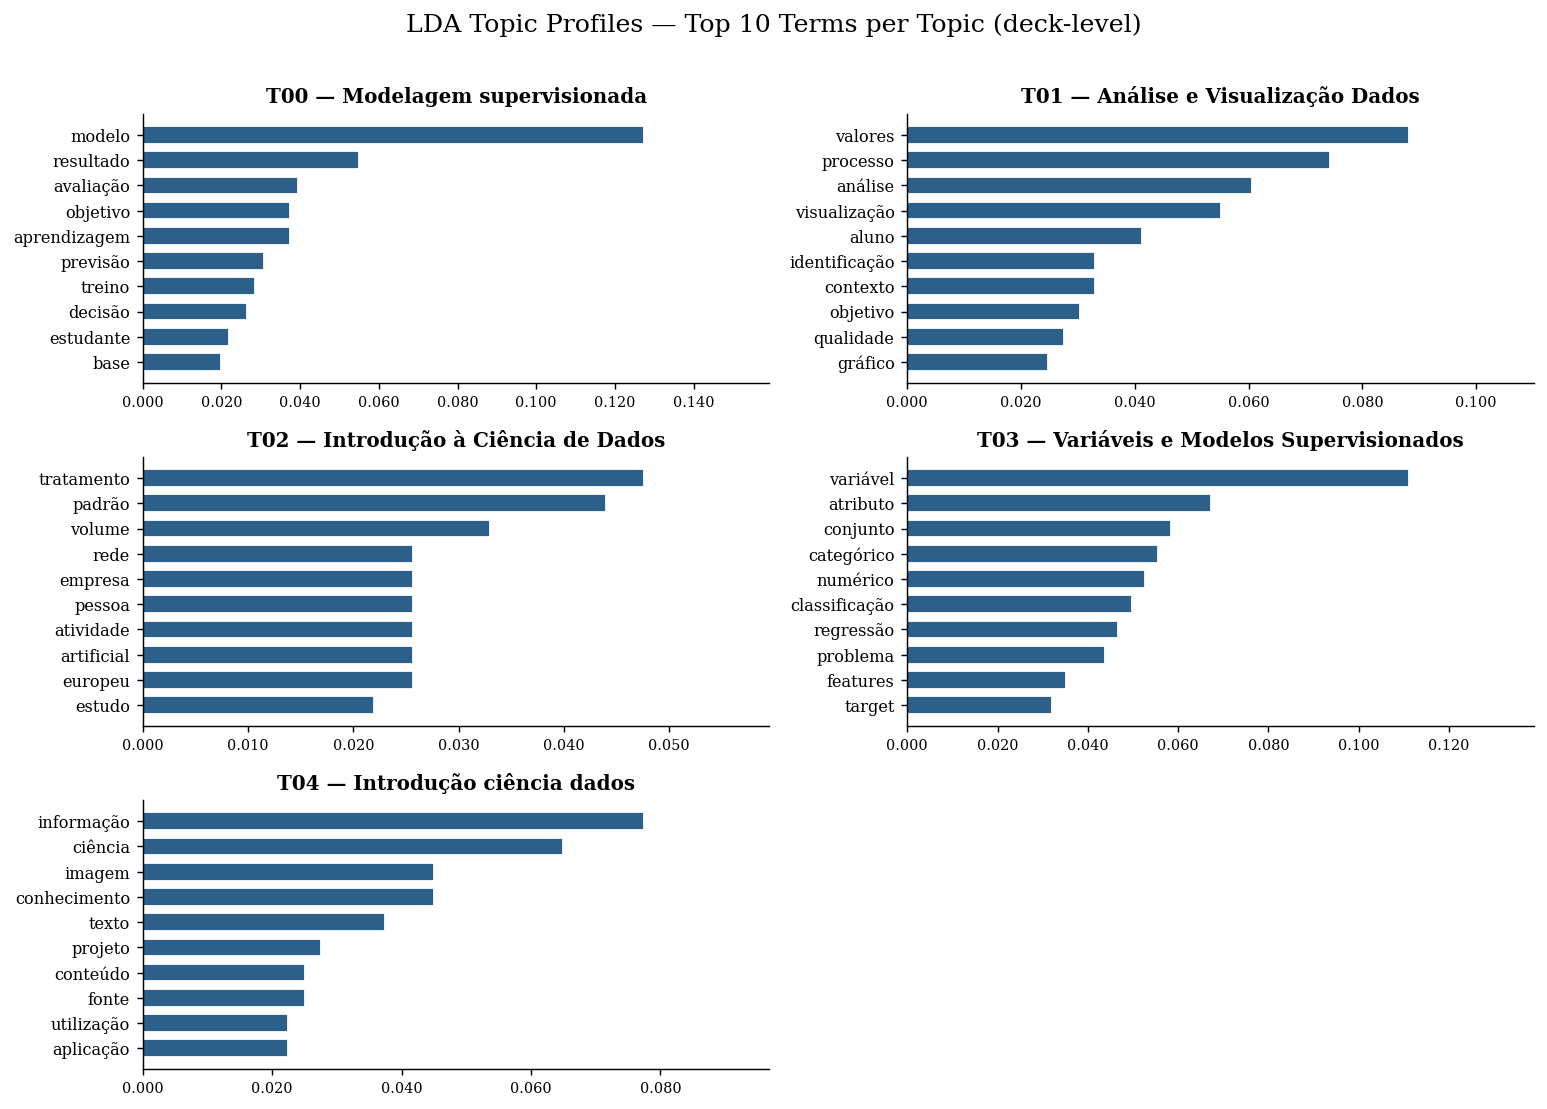

In [9]:
# Visualize topic profiles
TOP_VIS = 10
n_cols = 2
n_rows = (NUM_TOPICS + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, n_rows * 2.8))
axes = axes.flatten()

for i in range(NUM_TOPICS):
    terms   = lda.get_topic_words(i, top_n=TOP_VIS)
    words   = [w for w, _ in terms][::-1]
    weights = [p for _, p in terms][::-1]

    ax = axes[i]
    ax.barh(words, weights, color=PALETTE[0], edgecolor='white', height=0.7)
    ax.set_title(f'T{i:02d} — {TOPIC_LABELS[i]}', fontsize=11, fontweight='bold')
    ax.set_xlim(0, max(weights) * 1.25)
    ax.tick_params(axis='y', labelsize=9)
    ax.tick_params(axis='x', labelsize=8)
    ax.xaxis.set_major_formatter(mticker.FormatStrFormatter('%.3f'))

for j in range(NUM_TOPICS, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('LDA Topic Profiles — Top 10 Terms per Topic (deck-level)', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

               source_file  n_tokens  dominant_topic
0  icd_2_v1_cleaned_v7.csv       568               2
1  icd_6_v1_cleaned_v7.csv       410               1
2  icd_1_v1_cleaned_v7.csv       488               4
3  icd_9_v1_cleaned_v7.csv       270               4
4  icd_3_v1_cleaned_v7.csv       669               0
5  icd_5_v1_cleaned_v7.csv        58               4
6  icd_4_v1_cleaned_v7.csv       230               1
7  icd_7_v1_cleaned_v7.csv       523               3


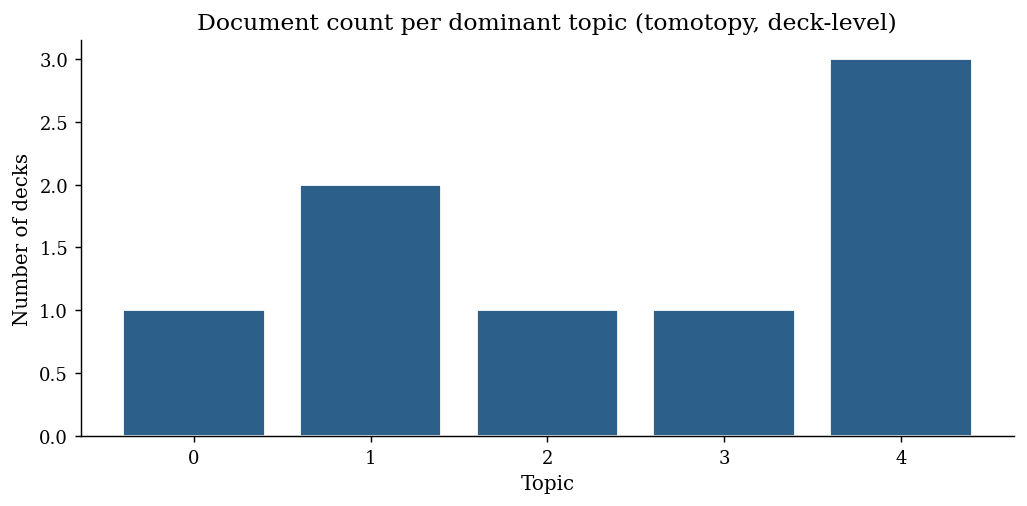

In [10]:
# Visualize document-topic distribution
train_docs_plot = train_docs.copy()
train_docs_plot['dominant_topic'] = [
    int(np.argmax(doc.get_topic_dist())) for doc in lda.docs
]

print(train_docs_plot[['source_file', 'n_tokens', 'dominant_topic']].to_string())

topic_dist = train_docs_plot['dominant_topic'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(topic_dist.index, topic_dist.values, color=PALETTE[0], edgecolor='white')
ax.set_xlabel('Topic')
ax.set_ylabel('Number of decks')
ax.set_title('Document count per dominant topic (tomotopy, deck-level)')
ax.set_xticks(range(NUM_TOPICS))
plt.tight_layout()
plt.show()

## 5. Initial Evaluation (C_v)

In [11]:
from tomotopy.coherence import Coherence

coh = Coherence(lda, coherence='c_v')
coherence_cv = coh.get_score()

print(f'Coherence (C_v): {coherence_cv:.4f}  (target > 0.50)')

Coherence (C_v): 0.6165  (target > 0.50)


## 6. Grid Search — Finding the Best K

K initial = 5 (must stay below n_docs=9; conservative starting point).  
Grid search over K ∈ [2, 8] to find the C_v-optimal K for this library.  
The best K from each library will be used in the cross-library comparison (Section 7).

k= 2  C_v=0.5698
k= 3  C_v=0.6534
k= 4  C_v=0.6023
k= 5  C_v=0.6165
k= 6  C_v=0.5715
k= 7  C_v=0.6131
k= 8  C_v=0.6205
k= 9  C_v=0.5868


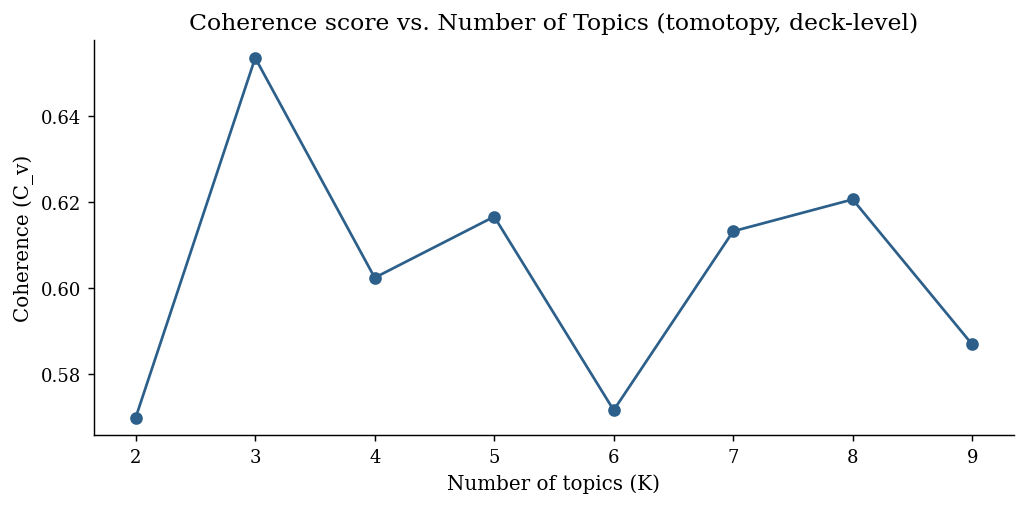


Best k=3  C_v=0.6534


In [12]:
# Coherence grid search over number of topics
# Helps to find the optimal K before committing to a final model and parameters.
TOPIC_RANGE = range(2, 10)

results = []
for k in TOPIC_RANGE:
    m = tp.LDAModel(k=k, alpha=ALPHA, eta=ETA, min_df=2, rm_top=0, seed=RANDOM_SEED)
    for token_list in train_texts:
        m.add_doc(token_list)
    m.train(0)
    m.train(ITERATIONS, workers=1)
    cv = Coherence(m, coherence='c_v').get_score()
    results.append({'k': k, 'coherence_cv': round(cv, 4)})
    print(f'k={k:2d}  C_v={cv:.4f}')

results_df = pd.DataFrame(results)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(results_df['k'], results_df['coherence_cv'], marker='o', color=PALETTE[0])
ax.set_xlabel('Number of topics (K)')
ax.set_ylabel('Coherence (C_v)')
ax.set_title('Coherence score vs. Number of Topics (tomotopy, deck-level)')
ax.set_xticks(list(TOPIC_RANGE))
plt.tight_layout()
plt.show()

best = results_df.loc[results_df['coherence_cv'].idxmax()]
print(f'\nBest k={int(best.k)}  C_v={best.coherence_cv}')

## 7. Cross-library Comparison

Trains models at two K values to compare how each library responds to K choices:
- **K_INITIAL**: domain-informed starting point
- **K_CGS_BEST**: optimal K found by tomotopy CGS grid search

> **Note:** At deck level both libraries converge on K=3, so cross-library K cross-application yields the same K_VB_BEST = K_CGS_BEST = 3.

In [13]:
K_INITIAL  = 5   # domain-informed prior: stay below n_docs (9)
K_CGS_BEST = 3   # tomotopy CGS grid search optimum (C_v peak)
K_VB_BEST  = 3   # gensim VB grid search optimum (same K at deck level)

K_GRID = [K_INITIAL, K_CGS_BEST]

models_by_k = {}
for k in K_GRID:
    m = tp.LDAModel(k=k, alpha=ALPHA, eta=ETA, min_df=2, rm_top=0, seed=RANDOM_SEED)
    for token_list in train_texts:
        m.add_doc(token_list)
    m.train(0)
    m.train(ITERATIONS, workers=1)
    models_by_k[k] = m
    print(f'Trained tomotopy CGS  k={k}  C_v={Coherence(m, coherence="c_v").get_score():.4f}')

print('\nCross-library C_v summary:')
for label, k in [('K_INITIAL', K_INITIAL), ('K_CGS_BEST (= K_VB_BEST)', K_CGS_BEST)]:
    cv = Coherence(models_by_k[k], coherence='c_v').get_score()
    print(f'  {label} (k={k}): C_v = {cv:.4f}')

Trained tomotopy CGS  k=5  C_v=0.6165
Trained tomotopy CGS  k=3  C_v=0.6534

Cross-library C_v summary:
  K_INITIAL (k=5): C_v = 0.6165
  K_CGS_BEST (= K_VB_BEST) (k=3): C_v = 0.6534


## 8. Final Evaluation

Evaluates the best model found by the grid search (K_CGS_BEST=3) with all metrics:
- **C_v coherence** (primary)
- **Train and test perplexity**
- **U_mass coherence**, **topic diversity**, **cosine similarity**, **Shannon entropy**, **exclusivity**

In [14]:
best_model = models_by_k[K_CGS_BEST]

# C_v coherence
best_cv = Coherence(best_model, coherence='c_v').get_score()
print(f'Best model (k={K_CGS_BEST}) — C_v: {best_cv:.4f}')

# Train perplexity — tomotopy native (in-sample)
train_perplexity = np.exp(-best_model.ll_per_word)
print(f'Best model (k={K_CGS_BEST}) — Train Perplexity: {train_perplexity:.2f}')

# Test perplexity — tomotopy native (out-of-sample)
total_ll    = 0.0
total_words = 0
for token_list in test_texts:
    doc = best_model.make_doc(token_list)
    _, ll = best_model.infer(doc)
    total_ll    += ll
    total_words += len(token_list)

test_perplexity = np.exp(-total_ll / total_words)
print(f'Best model (k={K_CGS_BEST}) — Test Perplexity: {test_perplexity:.2f}')

Best model (k=3) — C_v: 0.6534
Best model (k=3) — Train Perplexity: 417.16
Best model (k=3) — Test Perplexity: 13.62


### 8.1 U_mass Coherence

In [15]:
from tomotopy.coherence import Coherence

coh_umass = Coherence(best_model, coherence='u_mass')
coherence_umass = coh_umass.get_score()

print(f'Best model (k={K_CGS_BEST}) — U_mass: {coherence_umass:.4f}  (closer to 0 = better; range typically −14 to 0)')

Best model (k=3) — U_mass: -0.4498  (closer to 0 = better; range typically −14 to 0)


In [16]:
# Topic diversity: fraction of unique words across top-N words of all topics
# Dieng et al. (2020) — range [0, 1]; higher = less redundancy between topics
TOP_N_DIV = 25

all_top_words = []
for i in range(K_CGS_BEST):
    terms = best_model.get_topic_words(i, top_n=TOP_N_DIV)
    all_top_words.extend([w for w, _ in terms])

diversity = len(set(all_top_words)) / len(all_top_words)
print(f'Best model (k={K_CGS_BEST}) — Topic Diversity (top-{TOP_N_DIV}): {diversity:.4f}  (range 0–1; higher = more diverse)')

Best model (k=3) — Topic Diversity (top-25): 1.0000  (range 0–1; higher = more diverse)


In [17]:
# Mean pairwise cosine similarity over top-N topic word-probability vectors
# Lower = more distinct topics; range [0, 1]
from itertools import combinations
import numpy as np

TOP_N_COS = 10
vocab_size = best_model.num_vocabs

# Build word -> index mapping from tomotopy's _VocabDict
word2idx = {w: i for i, w in enumerate(best_model.vocabs)}

# Build topic vectors (full vocab, probability at each position)
topic_vectors = []
for i in range(K_CGS_BEST):
    vec = np.zeros(vocab_size)
    for w, p in best_model.get_topic_words(i, top_n=TOP_N_COS):
        if w in word2idx:
            vec[word2idx[w]] = p
    topic_vectors.append(vec)

sims = []
for a, b in combinations(topic_vectors, 2):
    cos = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-10)
    sims.append(cos)

mean_cos = np.mean(sims)
max_cos  = np.max(sims)
print(f'Best model (k={K_CGS_BEST}) — Cosine Similarity (top-{TOP_N_COS}): mean={mean_cos:.4f}, max={max_cos:.4f}  (lower = more distinct)')

Best model (k=3) — Cosine Similarity (top-10): mean=0.0000, max=0.0000  (lower = more distinct)


In [18]:
# Shannon entropy of topic-word distributions
# Higher = more diffuse topic; lower = more concentrated/specific
from scipy.stats import entropy as shannon_entropy

entropies = []
for i in range(K_CGS_BEST):
    probs = np.array(best_model.get_topic_word_dist(i))  # full vocab distribution
    entropies.append(shannon_entropy(probs))

mean_ent = np.mean(entropies)
print(f'Best model (k={K_CGS_BEST}) — Shannon Entropy: mean={mean_ent:.4f}  (higher = more diffuse)')
for i, e in enumerate(entropies):
    print(f'  T{i+1}: {e:.4f}')

Best model (k=3) — Shannon Entropy: mean=4.3500  (higher = more diffuse)
  T1: 4.2376
  T2: 4.0861
  T3: 4.7263


In [19]:
# Exclusivity: mean P(topic|word) over top-N words per topic
# Higher = words concentrated in that topic alone; lower = words shared across topics
TOP_N_EXC = 10

# Compute P(word|topic) matrix for all topics
topic_word_matrix = np.array([best_model.get_topic_word_dist(i) for i in range(K_CGS_BEST)])
# P(topic|word) via Bayes: normalise across topics for each word
topic_given_word = topic_word_matrix / (topic_word_matrix.sum(axis=0, keepdims=True) + 1e-10)

exclusivities = []
for i in range(K_CGS_BEST):
    top_indices = topic_word_matrix[i].argsort()[-TOP_N_EXC:]
    excl = topic_given_word[i, top_indices].mean()
    exclusivities.append(excl)

mean_excl = np.mean(exclusivities)
print(f'Best model (k={K_CGS_BEST}) — Exclusivity (top-{TOP_N_EXC}): mean={mean_excl:.4f}  (higher = more exclusive)')
for i, e in enumerate(exclusivities):
    print(f'  T{i+1}: {e:.4f}')

Best model (k=3) — Exclusivity (top-10): mean=0.9924  (higher = more exclusive)
  T1: 0.9795
  T2: 0.9992
  T3: 0.9985


### 8.6 Evaluation Summary

In [20]:
summary = {
    'Metric': ['C_v', 'U_mass', 'Train Perplexity', 'Test Perplexity',
               'Diversity (top-25)', 'Cosine Sim (mean)', 'Shannon Entropy', 'Exclusivity (top-10)'],
    'CGS k=3': [f'{best_cv:.2f}', f'{coherence_umass:.2f}', f'{train_perplexity:.2f}',
                f'{test_perplexity:.2f}', f'{diversity:.2f}', f'{mean_cos:.3f}',
                f'{mean_ent:.2f}', f'{mean_excl:.2f}'],
    'Direction': ['higher', 'closer to 0', 'lower', 'lower', 'higher', 'lower', 'lower', 'higher'],
}

summary_df = pd.DataFrame(summary).set_index('Metric')
summary_df

,CGS k=3,Direction
Metric,,
C_v,0.65,higher
U_mass,-0.45,closer to 0
Train Perplexity,417.16,lower
Test Perplexity,13.62,lower
Diversity (top-25),1.00,higher
Cosine Sim (mean),0.000,lower
Shannon Entropy,4.35,lower
Exclusivity (top-10),0.99,higher
